# ClimaCity Paris -- 01. Exploration avec l'API RDD (Jour 1 matin)

Premier contact avec l'historique Vélib' brut, **uniquement avec l'API RDD** :

1. lecture des 10 fichiers `.csv.gz` avec `sc.textFile()` et analyse du format brut ;
2. retrait de l'en-tête par `filter` et **parsing robuste** avec `map` ;
3. **évaluation paresseuse** : une chaîne de transformations ne calcule rien avant une action ;
4. comptage des relevés **par station** avec `reduceByKey`, puis usages de `flatMap` ;
5. anomalies et **trous de collecte** (pourquoi les fichiers vont de 11 à 34 Mo) ;
6. comparaison **Pandas / Spark** sur le même fichier ;
7. **10 partitions** en RDD contre **9** en DataFrame ;
8. lecture du **DAG** dans le Spark UI (stages, shuffle).

> **ADAPTATION.** L'énoncé demande de compter les relevés par station « sur l'année 2022 ». Le seul
> historique public couvre l'hiver 2020-2021 (26/11/2020 au 09/04/2021, voir le README) : on compte
> donc sur toute la période disponible.

## 1. SparkSession et SparkContext

Cellule commune à tous les carnets : configuration partagée, puis session locale. L'API RDD passe par le
`SparkContext` (`sc`), accessible depuis la session. Le Spark UI est ouvert pendant toute la durée du
carnet ; chaque action est nommée avec `sc.setJobDescription()` pour la retrouver dans l'onglet *Jobs*.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path("..", "scripts").resolve()))
from config import *          # chemins, SEED, SHUFFLE_PARTITIONS, creer_session()

import csv
import shutil
import time
from datetime import datetime, timezone
from operator import add
from zoneinfo import ZoneInfo

import pandas as pd
from pyspark import StorageLevel

spark = creer_session("ClimaCity-01-rdd-exploration")
sc = spark.sparkContext
print(f"Spark {spark.version} | master {sc.master} | parallélisme par défaut : {sc.defaultParallelism}")
print(f"Spark UI : {SPARK_UI} (application {sc.applicationId})")

Spark 3.5.3 | master local[*] | parallélisme par défaut : 8
Spark UI : http://localhost:4040 (application local-1793264336702)


## 2. Lecture brute avec `sc.textFile()`

`textFile` accepte un motif de chemin et lit directement le gzip. Le résultat est un RDD de **chaînes** :
Spark ne connaît ni les colonnes ni les types. Un fichier gzip n'est **pas découpable** (on ne peut pas
commencer la décompression au milieu) : chaque fichier donne exactement une partition.

In [2]:
sc.setJobDescription("Lecture brute : aperçu des premières lignes")
fichiers = sorted(VELIB_RAW.glob("velib_*.csv.gz"))
brut = sc.textFile(str(VELIB_RAW / "velib_*.csv.gz"))

print(f"{len(fichiers)} fichiers -> {brut.getNumPartitions()} partitions\n")
for ligne in brut.take(3):
    print(ligne)

10 fichiers -> 10 partitions



horodatage,capacite,velos_mecaniques,velos_electriques,nom_station,coordonnees,en_service
2020-11-26T12:59Z,35,4,5,Benjamin Godard - Victor Hugo,"48.86598,2.27572",True
2020-11-26T12:59Z,55,23,4,André Mazet - Saint-André des Arts,"48.85376,2.33910",True


Le schéma brut a 7 champs : `horodatage` (ISO 8601, UTC, à la minute), `capacite`, `velos_mecaniques`,
`velos_electriques`, `nom_station`, `coordonnees` et `en_service`. Deux pièges :

- il n'y a **ni identifiant de station ni nombre de bornettes libres** (on les reconstruira au carnet 02) ;
- `coordonnees` contient une **virgule entre guillemets** : un `split(",")` naïf coupe la latitude et la
  longitude en deux champs. Le module `csv` de Python, lui, respecte les guillemets.

In [3]:
exemple = brut.take(2)[1]
naif = exemple.split(",")
correct = next(csv.reader([exemple]))
print(f"split(',')  -> {len(naif)} champs : {naif}")
print(f"csv.reader  -> {len(correct)} champs : {correct}")

split(',')  -> 8 champs : ['2020-11-26T12:59Z', '35', '4', '5', 'Benjamin Godard - Victor Hugo', '"48.86598', '2.27572"', 'True']
csv.reader  -> 7 champs : ['2020-11-26T12:59Z', '35', '4', '5', 'Benjamin Godard - Victor Hugo', '48.86598,2.27572', 'True']


## 3. Parsing robuste

`parser_releve` convertit une ligne en tuple typé. Toute ligne inexploitable (tronquée, entier illisible,
date dans un autre format, `en_service` inconnu) renvoie `None` au lieu de lever une exception : une seule
ligne corrompue ne doit pas faire échouer une tâche sur 11 millions de lignes. On la teste d'abord sur
quelques lignes fabriquées, distribuées avec `sc.parallelize`.

In [4]:
FORMAT_HORODATAGE = "%Y-%m-%dT%H:%MZ"
# Indices des champs d'un relevé parsé (tuple, plus léger qu'un dictionnaire à sérialiser)
HORO, CAPA, MECA, ELEC, NOM, LAT, LON, SERVICE = range(8)


def parser_releve(ligne: str):
    """Transforme une ligne CSV brute en relevé typé, ou None si elle est inexploitable.

    Args:
        ligne: Ligne du fichier, par ex.
            ``'2020-11-26T12:59Z,35,4,5,Benjamin Godard,"48.86598,2.27572",True'``.

    Returns:
        Le tuple ``(horodatage, capacite, velos_mecaniques, velos_electriques, nom_station,
        latitude, longitude, en_service)``, l'horodatage étant un ``datetime`` en UTC ; ou
        ``None`` si la ligne n'a pas 7 champs ou si un champ ne se convertit pas.

    Example:
        >>> parser_releve('2020-11-26T12:59Z,35,4,5,Benjamin Godard,"48.86598,2.27572",True')[1:4]
        (35, 4, 5)
        >>> parser_releve("ligne tronquée") is None
        True
    """
    try:
        champs = next(csv.reader([ligne]))
        if len(champs) != 7 or champs[6] not in ("True", "False") or not champs[4].strip():
            return None
        horodatage, capacite, mecaniques, electriques, nom, coordonnees, en_service = champs
        latitude, longitude = (float(x) for x in coordonnees.split(","))
        return (
            datetime.strptime(horodatage, FORMAT_HORODATAGE).replace(tzinfo=timezone.utc),
            int(capacite), int(mecaniques), int(electriques), nom.strip(),
            latitude, longitude, en_service == "True",
        )
    except (ValueError, StopIteration):
        return None


lignes_test = [
    '2020-11-26T12:59Z,35,4,5,Benjamin Godard - Victor Hugo,"48.86598,2.27572",True',
    '2020-11-26T12:59Z,35,4,5,"Nom, avec virgule","48.86598,2.27572",False',
    '2020-11-26T12:59Z,35,quatre,5,Station,"48.86598,2.27572",True',
    '2020-11-26T12:59Z,35,4,5,Station',
    '26/11/2020 12:59,35,4,5,Station,"48.86598,2.27572",True',
    '2020-11-26T12:59Z,35,4,5,Station,"48.86598",True',
    '',
]
resultats = sc.parallelize(lignes_test).map(parser_releve).collect()
for ligne, resultat in zip(lignes_test, resultats):
    print(f"{'accepté' if resultat else 'rejeté '}  {ligne or '<ligne vide>'}")
assert [r is not None for r in resultats] == [True, True, False, False, False, False, False]

accepté  2020-11-26T12:59Z,35,4,5,Benjamin Godard - Victor Hugo,"48.86598,2.27572",True
accepté  2020-11-26T12:59Z,35,4,5,"Nom, avec virgule","48.86598,2.27572",False
rejeté   2020-11-26T12:59Z,35,quatre,5,Station,"48.86598,2.27572",True
rejeté   2020-11-26T12:59Z,35,4,5,Station
rejeté   26/11/2020 12:59,35,4,5,Station,"48.86598,2.27572",True
rejeté   2020-11-26T12:59Z,35,4,5,Station,"48.86598",True
rejeté   <ligne vide>


## 4. Chaîne de transformations et évaluation paresseuse

On enchaîne trois **transformations** : `filter` retire l'en-tête (présent une fois **par fichier**, donc
10 fois), `map` parse, `filter` écarte les rejets. Deux **accumulateurs** comptent au passage les en-têtes
et les lignes rejetées.

Rien n'est calculé à la définition : Spark n'enregistre que la **lignée** (*lineage*) du RDD, affichée par
`toDebugString()`. Les accumulateurs valent encore 0.

In [5]:
entete = brut.first()
acc_entetes = sc.accumulator(0)
acc_rejets = sc.accumulator(0)


def est_donnee(ligne: str) -> bool:
    """Indique si une ligne brute est une donnée (et non l'en-tête d'un des fichiers).

    Args:
        ligne: Ligne brute lue par ``textFile``.

    Returns:
        False pour une ligne d'en-tête (comptée dans ``acc_entetes``), True sinon.

    Example:
        >>> est_donnee("horodatage,capacite,velos_mecaniques,...")   # l'en-tête exact
        False
    """
    if ligne == entete:
        acc_entetes.add(1)
        return False
    return True


def parser_ou_compter(ligne: str):
    """Applique ``parser_releve`` et compte les rejets dans ``acc_rejets``.

    Args:
        ligne: Ligne de données brute.

    Returns:
        Le relevé typé, ou None si la ligne est rejetée.

    Example:
        >>> parser_ou_compter("ligne tronquée") is None   # et acc_rejets augmente de 1
        True
    """
    releve = parser_releve(ligne)
    if releve is None:
        acc_rejets.add(1)
    return releve


t0 = time.perf_counter()
releves = (
    brut
    .filter(est_donnee)
    .map(parser_ou_compter)
    .filter(lambda r: r is not None)
)
duree_definition = time.perf_counter() - t0

print(f"Chaîne définie en {duree_definition * 1000:.2f} ms")
print(f"Accumulateurs avant toute action : {acc_entetes.value} en-tête(s), {acc_rejets.value} rejet(s)\n")
print(releves.toDebugString().decode())

Chaîne définie en 0.33 ms
Accumulateurs avant toute action : 0 en-tête(s), 0 rejet(s)

(10) PythonRDD[7] at RDD at PythonRDD.scala:53 []
 |   /home/jovyan/data/velib/raw/velib_*.csv.gz MapPartitionsRDD[1] at textFile at NativeMethodAccessorImpl.java:0 []
 |   /home/jovyan/data/velib/raw/velib_*.csv.gz HadoopRDD[0] at textFile at NativeMethodAccessorImpl.java:0 []


Le RDD `releves` va servir à toutes les analyses suivantes : on le **persiste** (`MEMORY_AND_DISK`, pour
déborder sur disque plutôt que d'échouer si la mémoire du driver ne suffit pas). Le premier `count()`
déclenche réellement la lecture, la décompression et le parsing des 11 millions de lignes, et remplit le
cache ; le second relit le cache.

Les accumulateurs ne sont fiables ici que parce que le RDD est persisté : si une partition était
recalculée, ses lignes seraient comptées deux fois (Spark ne garantit l'unicité qu'à l'intérieur des
actions).

In [6]:
releves.persist(StorageLevel.MEMORY_AND_DISK)

sc.setJobDescription("count() n°1 : lecture + parsing + mise en cache")
t0 = time.perf_counter()
n_releves = releves.count()
duree_count_1 = time.perf_counter() - t0

sc.setJobDescription("count() n°2 : relecture du RDD persisté")
t0 = time.perf_counter()
releves.count()
duree_count_2 = time.perf_counter() - t0

print(f"{n_releves:,} relevés".replace(",", " "))
print(f"count() n°1 : {duree_count_1:5.1f} s  (lecture gzip + parsing + cache)")
print(f"count() n°2 : {duree_count_2:5.1f} s  (cache)")
print(f"En-têtes retirés : {acc_entetes.value} | lignes rejetées : {acc_rejets.value}")
assert acc_entetes.value == len(fichiers), "un en-tête par fichier attendu"

10 986 730 relevés
count() n°1 :  14.6 s  (lecture gzip + parsing + cache)
count() n°2 :   0.6 s  (cache)
En-têtes retirés : 10 | lignes rejetées : 0


## 5. Comptage des relevés par station avec `reduceByKey`

Sans identifiant, une station est repérée par son **nom et ses coordonnées**. `map` produit des paires
`(station, 1)` et `reduceByKey` les additionne : chaque partition pré-agrège ses propres clés
(*combiner*), puis seules les sommes partielles traversent le **shuffle**. Le résultat (environ 1 400
lignes) est assez petit pour être ramené au driver.

In [7]:
sc.setJobDescription("reduceByKey : relevés par station")
par_station = (
    releves
    .map(lambda r: ((r[NOM], r[LAT], r[LON]), 1))
    .reduceByKey(add)
)
comptes = par_station.collect()

sc.setJobDescription("distinct : noms de station")
n_noms = par_station.map(lambda kv: kv[0][0]).distinct().count()
total = sum(n for _, n in comptes)
assert total == n_releves, "la somme des comptes doit redonner le nombre de relevés"

tableau = (
    pd.DataFrame([(nom, lat, lon, n) for (nom, lat, lon), n in comptes],
                 columns=["nom_station", "latitude", "longitude", "releves"])
    .sort_values("releves", ascending=False, ignore_index=True)
)
print(f"{len(comptes)} couples (nom, coordonnées) pour {n_noms} noms distincts")
print(f"Relevés par station : min {tableau.releves.min()}, médiane {tableau.releves.median():.0f}, "
      f"max {tableau.releves.max()}  (nombre d'horodatages distincts : voir section 7)")
print(f"Partitions du RDD résultat : {par_station.getNumPartitions()}")
display(pd.concat([tableau.head(5), tableau.tail(5)]))

1405 couples (nom, coordonnées) pour 1396 noms distincts
Relevés par station : min 2, médiane 7866, max 7866  (nombre d'horodatages distincts : voir section 7)
Partitions du RDD résultat : 10


,nom_station,latitude,longitude,releves
0,Bobillot - Moulin des Prés,48.82866,2.35302,7866
1,Charonne - Robert et Sonia Delauney,48.85591,2.39257,7866
2,Saint-Sulpice,48.85165,2.33081,7866
3,Beaux-Arts - Bonaparte,48.85645,2.33485,7866
4,Thouin - Cardinal Lemoine,48.84505,2.34946,7866
1400,Arago - Paul Lafargue,48.88500,48.88500,680
1401,Parmentier - Abel rabaud,48.86921,2.37169,612
1402,station formation alfortville,48.77874,2.41977,5
1403,Jean Jaurès - Paul Lafargue,48.88501,2.24857,2
1404,Hôpital Européen Georges Pompidou,48.83815,2.27494,2


Les stations les mieux suivies ont un relevé à **chaque** passage du collecteur ; celles du bas du
classement ont ouvert ou fermé pendant l'hiver (ou changé de nom). À noter : `reduceByKey` sur un RDD
garde le nombre de partitions du parent (10) ; le réglage `spark.sql.shuffle.partitions = 8` ne
concerne que les DataFrames.

Il y a **plus de couples (nom, coordonnées) que de noms** : certains noms apparaissent à deux positions.
Pour savoir s'il s'agit de deux stations homonymes ou d'une station déplacée, on calcule pour chaque
couple sa période d'activité (`reduceByKey` sur un triplet min / max / compte), puis on regroupe par nom.

In [8]:
from math import asin, cos, radians, sin, sqrt


def distance_m(lat1: float, lon1: float, lat2: float, lon2: float) -> float:
    """Distance à vol d'oiseau entre deux points (formule de haversine).

    Args:
        lat1: Latitude du premier point, en degrés.
        lon1: Longitude du premier point, en degrés.
        lat2: Latitude du second point, en degrés.
        lon2: Longitude du second point, en degrés.

    Returns:
        La distance en mètres.

    Example:
        >>> round(distance_m(48.8566, 2.3522, 48.8584, 2.2945))   # Hôtel de Ville -> tour Eiffel
        4224
    """
    dlat, dlon = radians(lat2 - lat1), radians(lon2 - lon1)
    a = sin(dlat / 2) ** 2 + cos(radians(lat1)) * cos(radians(lat2)) * sin(dlon / 2) ** 2
    return 2 * 6_371_000 * asin(sqrt(a))


sc.setJobDescription("reduceByKey : période d'activité par (nom, coordonnées)")
periodes = (
    releves
    .map(lambda r: ((r[NOM], r[LAT], r[LON]), (r[HORO], r[HORO], 1)))
    .reduceByKey(lambda a, b: (min(a[0], b[0]), max(a[1], b[1]), a[2] + b[2]))
)
noms_multiples = (
    periodes
    .map(lambda kv: (kv[0][0], [(kv[0][1], kv[0][2]) + kv[1]]))
    .reduceByKey(add)                                  # concaténation des listes
    .filter(lambda kv: len(kv[1]) > 1)
    .collect()
)

lignes = []
for nom, positions in sorted(noms_multiples):
    (la1, lo1, *_), (la2, lo2, *_) = positions[:2]
    ecart = distance_m(la1, lo1, la2, lo2)
    for lat, lon, debut, fin, n in sorted(positions, key=lambda p: p[2]):
        lignes.append((nom, f"{lat:.5f}, {lon:.5f}", f"{debut:%d/%m/%Y}", f"{fin:%d/%m/%Y}", n,
                       round(ecart)))
display(pd.DataFrame(lignes, columns=["nom_station", "coordonnees", "premier", "dernier", "releves",
                                      "ecart_m"]))

# Cas inverse : une même position sous plusieurs noms (station renommée)
sc.setJobDescription("reduceByKey : noms par position")
positions_multiples = (
    periodes
    .map(lambda kv: ((kv[0][1], kv[0][2]), [(kv[0][0],) + kv[1]]))
    .reduceByKey(add)
    .filter(lambda kv: len(kv[1]) > 1)
    .collect()
)
display(pd.DataFrame(
    [(f"{lat:.5f}, {lon:.5f}", nom, f"{debut:%d/%m/%Y}", f"{fin:%d/%m/%Y}", n)
     for (lat, lon), noms in sorted(positions_multiples)
     for nom, debut, fin, n in sorted(noms, key=lambda p: p[1])],
    columns=["coordonnees", "nom_station", "premier", "dernier", "releves"]))

,nom_station,coordonnees,premier,dernier,releves,ecart_m
0,Chabanais - Petits Champs,"48.86728, 2.33673",26/11/2020,09/12/2020,1079,27
1,Chabanais - Petits Champs,"48.86704, 2.33672",09/12/2020,09/04/2021,6787,27
2,Château - République,"48.90593, 2.25363",26/11/2020,09/04/2021,7866,12766
3,Château - République,"48.86292, 2.41550",26/11/2020,09/04/2021,7866,12766
4,Hôpital Européen Georges Pompidou,"48.83770, 2.27537",26/11/2020,09/04/2021,7866,59
5,Hôpital Européen Georges Pompidou,"48.83815, 2.27494",09/04/2021,09/04/2021,2,59
6,Neuilly - Petit,"48.89929, 2.29669",26/11/2020,29/12/2020,2294,47
7,Neuilly - Petit,"48.89897, 2.29628",29/12/2020,09/04/2021,5572,47
8,Parc Floral du Bel Air,"48.83992, 2.43838",26/11/2020,12/02/2021,3978,71
9,Parc Floral du Bel Air,"48.83929, 2.43856",12/02/2021,09/04/2021,3888,71


,coordonnees,nom_station,premier,dernier,releves
0,"48.86921, 2.37169",Parmentier - Abel rabaud,26/11/2020,03/12/2020,612
1,"48.86921, 2.37169",Parmentier - Abel Rabaud,03/12/2020,09/04/2021,7254


Trois situations apparaissent. Au passage, le `strip()` du parsing a déjà fusionné trois noms qui ne différaient que par une espace finale (« Porte de Vincennes », « Place Nelson Mandela », « Hôpital Européen Georges Pompidou ») : sans lui, on compterait 1 399 noms.

- **Stations déplacées ou recalées** (Chabanais - Petits Champs, Neuilly - Petit, Parc Floral du Bel Air, Hôpital Européen Georges Pompidou) : moins de 100 m entre les deux positions, et des périodes qui se succèdent sans se chevaucher. C'est la même station.
- **Vrais homonymes** (Château - République, Place Nelson Mandela, Place de l'Eglise, Place de l'Europe, Université) : 4 à 13 km d'écart, et les deux positions relevées à chaque passage pendant tout l'hiver. Ce sont deux stations distinctes, dans deux communes différentes.
- **Station renommée** : « Parmentier - Abel rabaud » devient « Parmentier - Abel Rabaud » le 03/12/2020, à la même position (correction de casse).

Conséquence pour le carnet 02 : ni le nom seul ni le couple (nom, coordonnées) ne font un bon identifiant. On rattachera chaque relevé à la **station GBFS la plus proche**, ce qui départage les homonymes par la distance.

## 6. `flatMap` : zéro, un ou plusieurs éléments par relevé

`map` produit exactement un élément par entrée ; `flatMap` en produit **un nombre quelconque**, y compris
zéro. Premier usage : éclater chaque relevé en deux paires `(type de vélo, nombre)` et ignorer les
stations hors service (liste vide), puis additionner par type.

In [9]:
def velos_par_type(releve) -> list:
    """Éclate un relevé en paires (type de vélo, nombre de vélos disponibles).

    Args:
        releve: Relevé typé produit par ``parser_releve``.

    Returns:
        ``[("mecaniques", n), ("electriques", m)]`` pour une station en service, ``[]`` sinon.

    Example:
        >>> velos_par_type((None, 35, 4, 5, "Nom", 48.8, 2.3, True))
        [('mecaniques', 4), ('electriques', 5)]
    """
    if not releve[SERVICE]:
        return []
    return [("mecaniques", releve[MECA]), ("electriques", releve[ELEC])]


sc.setJobDescription("flatMap + reduceByKey : vélos par type")
totaux = releves.flatMap(velos_par_type).reduceByKey(add).collectAsMap()
part_electrique = totaux["electriques"] / (totaux["electriques"] + totaux["mecaniques"])
print(f"Vélos observés (somme des relevés en service) : {totaux}")
print(f"Part des vélos électriques parmi les vélos disponibles : {part_electrique:.1%}")

Vélos observés (somme des relevés en service) : {'electriques': 38471859, 'mecaniques': 86188319}
Part des vélos électriques parmi les vélos disponibles : 30.9%


Second usage : un relevé peut présenter **plusieurs anomalies** ou aucune. `anomalies` renvoie la liste
de ses étiquettes ; `flatMap` aplatit ces listes et `countByValue` (une action) compte chaque étiquette.
Ces anomalies seront traitées au nettoyage du carnet 02 ; ici on ne fait que les mesurer.

In [10]:
def anomalies(releve) -> list:
    """Liste les anomalies d'un relevé (souvent aucune).

    Args:
        releve: Relevé typé produit par ``parser_releve``.

    Returns:
        Les étiquettes parmi ``capacite_nulle_ou_negative``, ``velos_negatifs``,
        ``velos_superieurs_capacite``, ``coordonnees_hors_zone`` (hors de la boîte englobante
        de la métropole) et ``hors_service``.

    Example:
        >>> anomalies((None, 0, 3, 0, "Nom", 48.8, 2.3, False))
        ['capacite_nulle_ou_negative', 'velos_superieurs_capacite', 'hors_service']
    """
    _, capacite, mecaniques, electriques, _, latitude, longitude, en_service = releve
    etiquettes = []
    if capacite <= 0:
        etiquettes.append("capacite_nulle_ou_negative")
    if mecaniques < 0 or electriques < 0:
        etiquettes.append("velos_negatifs")
    if mecaniques + electriques > capacite:
        etiquettes.append("velos_superieurs_capacite")
    if not (48.6 <= latitude <= 49.1 and 2.0 <= longitude <= 2.7):
        etiquettes.append("coordonnees_hors_zone")
    if not en_service:
        etiquettes.append("hors_service")
    return etiquettes


sc.setJobDescription("flatMap + countByValue : anomalies")
compte_anomalies = releves.flatMap(anomalies).countByValue()
for etiquette, n in sorted(compte_anomalies.items(), key=lambda kv: -kv[1]):
    print(f"{etiquette:<28} {n:>9,}  ({n / n_releves:.2%})".replace(",", " "))

hors_service                   217 466  (1.98%)
capacite_nulle_ou_negative      64 762  (0.59%)
velos_superieurs_capacite        2 036  (0.02%)
coordonnees_hors_zone              680  (0.01%)


Lecture des anomalies (une même ligne peut en cumuler plusieurs) :

- **hors_service** (2 %) : la station est relevée mais fermée ; ses compteurs ne reflètent pas l'usage.
- **capacite_nulle_ou_negative** (0,6 %) : capacité 0, typiquement une station en travaux ou pas encore ouverte. Le taux d'occupation n'y est pas défini (division par zéro).
- **velos_superieurs_capacite** (0,02 %) : plus de vélos que de bornettes, ce qui arrive sur le terrain (vélos rattachés en surplus) ou quand la capacité n'est pas à jour. Le taux d'occupation dépasserait 1.
- **coordonnees_hors_zone** : ce sont exactement les 680 relevés d'« Arago - Paul Lafargue », dont la longitude vaut la latitude (48,885, visible en bas du classement de la section 5). Erreur de la source : le rattachement au référentiel GBFS devra en tenir compte.

Aucune valeur négative ni aucune ligne illisible : la source est propre sur la forme, les problèmes sont sur le fond.

## 7. Trous de collecte : pourquoi les fichiers n'ont pas la même taille

Les fichiers couvrent chacun une quinzaine (en UTC), mais leur taille varie du simple au triple. On compte,
par quinzaine, les relevés et les **passages du collecteur** (horodatages distincts). Toutes les stations
étant relevées au même instant, un horodatage correspond à un passage.

In [11]:
def quinzaine(horodatage: datetime) -> str:
    """Étiquette de quinzaine d'un horodatage, identique au nom des fichiers de ``collecte.py``.

    Args:
        horodatage: Instant UTC.

    Returns:
        ``AAAA-MM-A`` (jours 1 à 15) ou ``AAAA-MM-B`` (jours 16 et suivants).

    Example:
        >>> quinzaine(datetime(2021, 1, 16, 8, 0))
        '2021-01-B'
    """
    return f"{horodatage:%Y-%m}-{'A' if horodatage.day <= 15 else 'B'}"


sc.setJobDescription("reduceByKey : relevés par horodatage")
par_horodatage = releves.map(lambda r: (r[HORO], 1)).reduceByKey(add).persist()

sc.setJobDescription("reduceByKey : bilan par quinzaine")
bilan = (
    par_horodatage
    .map(lambda kv: (quinzaine(kv[0]), (1, kv[1], {kv[0].date()})))
    .reduceByKey(lambda a, b: (a[0] + b[0], a[1] + b[1], a[2] | b[2]))
    .collectAsMap()
)

lignes = []
for f in fichiers:
    q = f.stem.removeprefix("velib_").removesuffix(".csv")
    passages, n, jours = bilan[q]
    lignes.append((q, f.stat().st_size / 1e6, n, len(jours), passages, passages / len(jours),
                   n / passages, f.stat().st_size / n))
bilan_quinzaines = pd.DataFrame(lignes, columns=[
    "quinzaine", "taille_mo", "releves", "jours", "passages", "passages_par_jour",
    "stations_par_passage", "octets_par_releve"])
display(bilan_quinzaines.round(1))

,quinzaine,taille_mo,releves,jours,passages,passages_par_jour,stations_par_passage,octets_par_releve
0,2020-11-B,11.6,549021,5,393,78.6,1397.0,21.1
1,2020-12-A,34.4,1630299,15,1167,77.8,1397.0,21.1
2,2020-12-B,24.9,1179068,16,844,52.8,1397.0,21.1
3,2021-01-A,15.2,720852,15,516,34.4,1397.0,21.1
4,2021-01-B,16.8,794893,16,569,35.6,1397.0,21.1
5,2021-02-A,21.6,1024001,12,733,61.1,1397.0,21.1
6,2021-02-B,25.4,1206345,13,864,66.5,1396.2,21.1
7,2021-03-A,26.4,1253613,15,898,59.9,1396.0,21.1
8,2021-03-B,33.9,1608192,16,1152,72.0,1396.0,21.1
9,2021-04-A,21.5,1020446,9,730,81.1,1397.9,21.1


Deux colonnes sont constantes : **~1 397 stations par passage** et **21,1 octets compressés par relevé**. La taille d'un fichier est donc proportionnelle à son nombre de passages, et l'écart de 11,6 à 34,4 Mo s'explique par deux causes :

- des **quinzaines incomplètes** : 2020-11-B ne couvre que 5 jours (l'historique commence le 26/11), 2021-04-A 9 jours (il s'arrête le 09/04) et 2021-02-A 12 jours sur 15 (trou de près de 4 jours, voir plus bas) ;
- une **fréquence de collecte variable** : environ 78 passages par jour (un toutes les 18 min) début décembre, mais 35 seulement en janvier (un toutes les 41 min). Les deux quinzaines de janvier sont complètes et pourtant deux fois plus légères que 2020-12-A.

Le nombre de stations relevées, lui, ne varie pas : les écarts de taille viennent de **trous de collecte**, pas de stations qui disparaissent.

Pour localiser les trous, on calcule l'**écart entre deux passages consécutifs**, toujours en RDD : les
horodatages sont triés (`sortBy`), numérotés (`zipWithIndex`), puis chaque passage `i` est joint au
passage `i + 1` (`join` sur l'indice).

In [12]:
sc.setJobDescription("sortBy + zipWithIndex + join : écarts entre passages")
numerotes = par_horodatage.keys().sortBy(lambda h: h).zipWithIndex().map(lambda kv: (kv[1], kv[0]))
suivants = numerotes.map(lambda kv: (kv[0] - 1, kv[1]))
ecarts = (
    numerotes.join(suivants)
    .map(lambda kv: (kv[1][0], (kv[1][1] - kv[1][0]).total_seconds() / 60))
    .persist()
)

stats = ecarts.values().stats()
bornes = [0, 10, 15, 20, 30, 60, 180, 24 * 60, 10 * 24 * 60]
_, effectifs = ecarts.values().histogram(bornes)
print(f"{stats.count()} écarts | moyenne {stats.mean():.1f} min | écart-type {stats.stdev():.1f} min | "
      f"min {stats.min():.0f} min | max {stats.max() / 60:.1f} h\n")
for bas, haut, n in zip(bornes, bornes[1:], effectifs):
    print(f"  [{bas:>5} ; {haut:>5}[ min : {n:>5}")

print("\nLes 5 plus grands trous :")
for debut, minutes in ecarts.takeOrdered(5, key=lambda kv: -kv[1]):
    print(f"  à partir du {debut:%d/%m/%Y %H:%M} UTC : {minutes / 60:5.1f} h sans relevé")

7865 écarts | moyenne 24.5 min | écart-type 63.3 min | min 1 min | max 91.8 h

  [    0 ;    10[ min :   337
  [   10 ;    15[ min :  1435
  [   15 ;    20[ min :  1742
  [   20 ;    30[ min :  2613
  [   30 ;    60[ min :  1547
  [   60 ;   180[ min :   188
  [  180 ;  1440[ min :     2
  [ 1440 ; 14400[ min :     1

Les 5 plus grands trous :
  à partir du 04/02/2021 18:54 UTC :  91.8 h sans relevé
  à partir du 01/12/2020 16:48 UTC :   3.7 h sans relevé
  à partir du 28/01/2021 03:44 UTC :   3.4 h sans relevé
  à partir du 15/03/2021 19:48 UTC :   2.2 h sans relevé
  à partir du 22/03/2021 19:48 UTC :   2.1 h sans relevé


Le nombre de passages par jour (date de Paris) rend ces trous visibles. La série a environ 135 points :
on la ramène au driver pour la tracer.

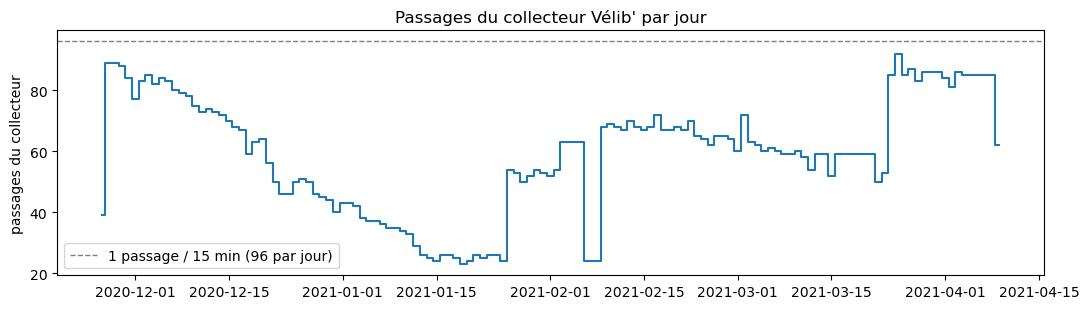

Jours sans aucun relevé : 3


In [13]:
import matplotlib.pyplot as plt

PARIS = ZoneInfo("Europe/Paris")
sc.setJobDescription("countByValue : passages par jour (heure de Paris)")
passages_jour = par_horodatage.keys().map(lambda h: h.astimezone(PARIS).date()).countByValue()
serie = pd.Series(passages_jour).sort_index()

fig, ax = plt.subplots(figsize=(11, 3.2))
serie.plot(ax=ax, drawstyle="steps-mid")
ax.axhline(96, color="grey", linestyle="--", linewidth=1, label="1 passage / 15 min (96 par jour)")
ax.set_ylabel("passages du collecteur")
ax.set_title("Passages du collecteur Vélib' par jour")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()
print(f"Jours sans aucun relevé : {pd.date_range(serie.index.min(), serie.index.max()).size - serie.size}")

Le collecteur ne passe **pas toutes les 15 minutes** : l'écart moyen est de 24,5 min, la médiane se situe entre 20 et 30 min, et la distribution a une longue traîne. On retient :

- un **trou majeur de 91,8 h**, du 04/02/2021 18:54 au 08/02/2021 14:40 UTC : ce sont les trois jours sans aucun relevé du graphique (5 au 7 février) ;
- quelques coupures de 2 à 4 h et près de 200 écarts compris entre 1 et 3 h ;
- en janvier, une collecte nettement plus espacée (palier vers 35 passages par jour).

Conséquence pour le carnet 05 : les features retardées « t-1 » et « t-4 » ne peuvent pas être prises comme « la ligne précédente » ; il faudra contrôler l'écart de temps réel entre deux relevés.

## 8. Comparaison Pandas / Spark sur le même fichier

On compte les relevés par station sur le **plus gros fichier** des deux façons : `pandas.read_csv` +
`groupby`, et la chaîne RDD ci-dessus. Pour Spark on mesure trois variantes : le fichier seul (une seule
partition, puisqu'un gzip n'est pas découpable), le même fichier **redistribué** en 8 partitions après la
lecture, et les **10 fichiers** (10 partitions en parallèle). Chaque mesure garde la meilleure de deux
exécutions.

Pandas n'est utilisé ici que pour la comparaison demandée par l'énoncé, sur un fichier.

In [14]:
def chronometrer(fonction, repetitions: int = 2):
    """Exécute une fonction plusieurs fois et garde la durée la plus courte.

    Args:
        fonction: Fonction sans argument à mesurer.
        repetitions: Nombre d'exécutions.

    Returns:
        Le couple ``(durée minimale en secondes, résultat de la dernière exécution)``.

    Example:
        >>> duree, resultat = chronometrer(lambda: sum(range(1000)))
        >>> resultat
        499500
    """
    durees = []
    for _ in range(repetitions):
        t0 = time.perf_counter()
        resultat = fonction()
        durees.append(time.perf_counter() - t0)
    return min(durees), resultat


def compter_par_station_rdd(lignes_brutes):
    """Chaîne RDD complète : en-tête, parsing, comptage des relevés par station.

    Args:
        lignes_brutes: RDD de lignes CSV brutes (avec en-tête).

    Returns:
        La liste ``[((nom, latitude, longitude), nombre_de_releves), ...]``.

    Example:
        >>> len(compter_par_station_rdd(sc.textFile(str(fichiers[0])))) > 1000
        True
    """
    return (
        lignes_brutes
        .filter(lambda l: l != entete)
        .map(parser_releve)
        .filter(lambda r: r is not None)
        .map(lambda r: ((r[NOM], r[LAT], r[LON]), 1))
        .reduceByKey(add)
        .collect()
    )


def compter_par_station_pandas(chemin):
    """Équivalent Pandas : lecture complète en mémoire puis groupby.

    Args:
        chemin: Fichier ``.csv.gz``.

    Returns:
        Le couple ``(comptes, octets)`` : une ``Series`` du nombre de relevés indexée par
        (nom_station, coordonnees), et la mémoire occupée par le DataFrame lu.

    Example:
        >>> comptes, octets = compter_par_station_pandas(fichiers[0])
        >>> comptes.sum() > 0
        True
    """
    pdf = pd.read_csv(chemin)
    return pdf.groupby(["nom_station", "coordonnees"]).size(), pdf.memory_usage(deep=True).sum()


gros = max(fichiers, key=lambda f: f.stat().st_size)
print(f"Fichier de test : {gros.name} ({gros.stat().st_size / 1e6:.1f} Mo)")

t_pandas, (res_pandas, octets_pandas) = chronometrer(lambda: compter_par_station_pandas(gros))

sc.setJobDescription("Pandas / Spark : 1 fichier, 1 partition")
t_spark_1, res_spark_1 = chronometrer(lambda: compter_par_station_rdd(sc.textFile(str(gros))))

sc.setJobDescription("Pandas / Spark : 1 fichier, repartition(8)")
t_spark_8, _ = chronometrer(
    lambda: compter_par_station_rdd(sc.textFile(str(gros)).repartition(sc.defaultParallelism)))

sc.setJobDescription("Pandas / Spark : 10 fichiers, 10 partitions")
t_spark_10, _ = chronometrer(
    lambda: compter_par_station_rdd(sc.textFile(str(VELIB_RAW / "velib_*.csv.gz"))))

n_gros = int(res_pandas.sum())
assert n_gros == sum(n for _, n in res_spark_1), "Pandas et Spark doivent trouver le même total"
assert len(res_pandas) == len(res_spark_1)

comparaison = pd.DataFrame([
    ("Pandas", gros.name, n_gros, t_pandas),
    ("Spark RDD, 1 partition", gros.name, n_gros, t_spark_1),
    ("Spark RDD, repartition(8)", gros.name, n_gros, t_spark_8),
    ("Spark RDD, 10 partitions", "10 fichiers", n_releves, t_spark_10),
], columns=["methode", "donnees", "lignes", "duree_s"])
comparaison["lignes_par_s"] = (comparaison.lignes / comparaison.duree_s).round(-3)
display(comparaison.round(2))
print(f"Mémoire du DataFrame Pandas : {octets_pandas / 1e6:.0f} Mo pour {gros.name}")
print(f"Pandas extrapolé aux 10 fichiers (séquentiel) : ~{t_pandas * n_releves / n_gros:.0f} s "
      f"et ~{octets_pandas * n_releves / n_gros / 1e9:.1f} Go en mémoire")

Fichier de test : velib_2020-12-A.csv.gz (34.4 Mo)


,methode,donnees,lignes,duree_s,lignes_par_s
0,Pandas,velib_2020-12-A.csv.gz,1630299,2.03,801000.0
1,"Spark RDD, 1 partition",velib_2020-12-A.csv.gz,1630299,7.88,207000.0
2,"Spark RDD, repartition(8)",velib_2020-12-A.csv.gz,1630299,2.30,708000.0
3,"Spark RDD, 10 partitions",10 fichiers,10986730,11.50,955000.0


Mémoire du DataFrame Pandas : 440 Mo pour velib_2020-12-A.csv.gz
Pandas extrapolé aux 10 fichiers (séquentiel) : ~14 s et ~3.0 Go en mémoire


Sur un seul fichier, **Pandas gagne** : environ 2 s contre 8 s pour Spark avec une partition. Trois raisons :

- **le surcoût de l'API RDD en Python** : la JVM lit et décompresse, mais chaque ligne est ensuite sérialisée vers un processus Python, parsée par `csv` et `strptime` en Python pur, puis renvoyée à la JVM. `pandas.read_csv` fait tout le parsing en C, de façon vectorisée ;
- **l'absence de parallélisme** : un gzip étant indivisible, il n'y a qu'une tâche, donc un seul cœur sur 8 ;
- **les coûts fixes** de Spark (planification, shuffle) pèsent lourd sur un petit volume.

`repartition(8)` rétablit le parallélisme du parsing (la décompression reste séquentielle) au prix d'un shuffle : Spark rejoint presque Pandas. Sur les **10 fichiers**, 10 tâches tournent en parallèle et Spark traite environ 0,9 million de lignes par seconde, autant que Pandas sur un seul fichier. Pandas, lui, lirait les fichiers l'un après l'autre (~14 s) et surtout il lui faudrait **environ 3 Go de mémoire** pour les garder ensemble, près de la moitié du conteneur ; Spark traite les partitions en flux et ne garde que les sommes partielles.

À cette échelle (11 M lignes, 230 Mo compressés), Spark n'est donc pas plus rapide que Pandas : son intérêt est de **passer à l'échelle** sans changer le code. L'API DataFrame (carnet 02), qui parse dans la JVM sans passer par Python, supprimera l'essentiel du surcoût mesuré ici.

## 9. 10 partitions en RDD, 9 en DataFrame

Les deux API ne découpent pas les fichiers de la même manière :

- `sc.textFile` (format d'entrée Hadoop) crée une partition par bloc de fichier ; un gzip étant
  indivisible, on obtient **une partition par fichier**, soit 10 ;
- le lecteur de fichiers des DataFrames **regroupe** les petits fichiers. Il vise des partitions de
  `maxSplitBytes = min(maxPartitionBytes, max(openCostInBytes, octets_par_coeur))` octets, où
  `octets_par_coeur = (taille totale + nb_fichiers × openCostInBytes) / parallélisme`, et compte chaque
  ouverture de fichier comme `openCostInBytes` (4 Mo) de données. Les fichiers, triés du plus gros au plus
  petit, remplissent les partitions tant qu'elles ne dépassent pas ce seuil.

On reproduit ce calcul, puis on le confronte à la répartition réelle (`spark_partition_id()` et
`input_file_name()`).

In [15]:
from pyspark.sql import functions as F

sc.setJobDescription("DataFrame : lecture de l'en-tête CSV")
df_csv = spark.read.csv(str(VELIB_RAW / "velib_*.csv.gz"), header=True)

conf_sql = spark._jsparkSession.sessionState().conf()     # valeurs effectives, en octets
max_partition = conf_sql.filesMaxPartitionBytes()
cout_ouverture = conf_sql.filesOpenCostInBytes()
tailles = {f.name: f.stat().st_size for f in fichiers}
octets_par_coeur = (sum(tailles.values()) + len(tailles) * cout_ouverture) / sc.defaultParallelism
max_split = min(max_partition, max(cout_ouverture, octets_par_coeur))

# Rangement des fichiers, comme FilePartition.getFilePartitions dans Spark 3.5
prevues, courante, remplissage = [], [], 0
for nom, taille in sorted(tailles.items(), key=lambda kv: -kv[1]):
    if courante and remplissage + taille > max_split:
        prevues.append(courante)
        courante, remplissage = [], 0
    courante.append(nom)
    remplissage += taille + cout_ouverture
prevues.append(courante)

sc.setJobDescription("DataFrame : fichiers par partition")
reelles = (
    df_csv.select(F.spark_partition_id().alias("partition"),
                  F.element_at(F.split(F.input_file_name(), "/"), -1).alias("fichier"))
    .distinct()
    .groupBy("partition").agg(F.sort_array(F.collect_list("fichier")).alias("fichiers"))
    .orderBy("partition")
    .collect()
)

print(f"maxSplitBytes = min({max_partition / 2**20:.0f} Mio, max({cout_ouverture / 2**20:.0f} Mio, "
      f"{octets_par_coeur / 2**20:.1f} Mio)) = {max_split / 2**20:.1f} Mio")
print(f"Partitions prévues : {len(prevues)} | DataFrame : {df_csv.rdd.getNumPartitions()} | "
      f"textFile : {brut.getNumPartitions()}\n")
for ligne in reelles:
    print(f"  partition {ligne.partition} : " +
          " + ".join(f"{f} ({tailles[f] / 2**20:.1f} Mio)" for f in ligne.fichiers))
assert sorted(map(sorted, prevues)) == sorted(list(l.fichiers) for l in reelles)

maxSplitBytes = min(128 Mio, max(4 Mio, 32.6 Mio)) = 32.6 Mio
Partitions prévues : 9 | DataFrame : 9 | textFile : 10

  partition 0 : velib_2020-12-A.csv.gz (32.8 Mio)
  partition 1 : velib_2021-03-B.csv.gz (32.3 Mio)
  partition 2 : velib_2021-03-A.csv.gz (25.2 Mio)
  partition 3 : velib_2021-02-B.csv.gz (24.3 Mio)
  partition 4 : velib_2020-12-B.csv.gz (23.8 Mio)
  partition 5 : velib_2021-02-A.csv.gz (20.6 Mio)
  partition 6 : velib_2021-04-A.csv.gz (20.5 Mio)
  partition 7 : velib_2021-01-B.csv.gz (16.0 Mio)
  partition 8 : velib_2020-11-B.csv.gz (11.1 Mio) + velib_2021-01-A.csv.gz (14.5 Mio)


Le calcul reproduit exactement la répartition de Spark. Le seuil vaut 32,6 Mio : (221 Mio de données + 10 × 4 Mio de coût d'ouverture) / 8 cœurs. Avec le coût d'ouverture, aucun couple de fichiers ne tient sous ce seuil, sauf les deux plus petits, 2021-01-A (14,5 Mio) et 2020-11-B (11,1 Mio) : **9 partitions**. `textFile` ne fait pas ce regroupement, d'où **10 partitions**.

Avec 8 cœurs, 9 ou 10 tâches imposent une seconde « vague » d'une ou deux tâches, et la durée de lecture est fixée par le plus gros fichier (32,8 Mio). L'écart de taille entre fichiers (de 11 à 33 Mio) crée donc un petit **déséquilibre** (*skew*) de lecture, qu'aucun réglage ne corrige tant que les fichiers restent en gzip : seul un format découpable comme Parquet (carnet 02) ou un `repartition` après la lecture le résorbe.

## 10. Lecture du DAG dans le Spark UI

Chaque action a produit un **job** visible sur http://localhost:4040/jobs. Un job est découpé en
**stages** aux frontières de **shuffle** : `reduceByKey` doit regrouper toutes les valeurs d'une même clé
sur la même partition, ce qui impose d'écrire puis de relire des données entre exécuteurs.

Plutôt qu'une capture d'écran, on interroge l'**API REST** du Spark UI, qui expose les mêmes chiffres que
l'onglet *Stages*. La lignée du comptage par station montre la même coupure (le décalage d'indentation
marque le shuffle).

In [16]:
import requests

api = f"{sc.uiWebUrl}/api/v1/applications/{sc.applicationId}"
jobs = requests.get(f"{api}/jobs", timeout=10).json()


def resume_job(description: str) -> pd.DataFrame:
    """Résume les stages du dernier job portant une description donnée.

    Args:
        description: Texte passé à ``sc.setJobDescription`` avant l'action.

    Returns:
        Un DataFrame Pandas d'une ligne par stage : tâches, durée, entrée, shuffle écrit et lu.

    Example:
        >>> resume_job("reduceByKey : relevés par station")   # doctest: +SKIP
    """
    job = next(j for j in jobs if j.get("description") == description)
    lignes = []
    for id_stage in sorted(job["stageIds"]):
        tentatives = requests.get(f"{api}/stages/{id_stage}", timeout=10).json()
        if not tentatives:
            continue
        s = tentatives[0]
        lignes.append((job["jobId"], id_stage, s["status"], s["name"], s["numTasks"],
                       s["executorRunTime"] / 1000, s["inputBytes"] / 1e6,
                       s["shuffleWriteBytes"] / 1e3, s["shuffleReadBytes"] / 1e3))
    return pd.DataFrame(lignes, columns=["job", "stage", "statut", "nom", "taches", "calcul_s",
                                         "entree_mo", "shuffle_ecrit_ko", "shuffle_lu_ko"])


print(par_station.toDebugString().decode())
display(pd.concat([resume_job(d) for d in [
    "count() n°1 : lecture + parsing + mise en cache",
    "reduceByKey : relevés par station",
    "Pandas / Spark : 10 fichiers, 10 partitions",
]]).round(2))

(10) PythonRDD[14] at collect at /tmp/ipykernel_8418/1417353962.py:7 []
 |   MapPartitionsRDD[13] at mapPartitions at PythonRDD.scala:160 []
 |   ShuffledRDD[12] at partitionBy at NativeMethodAccessorImpl.java:0 []
 +-(10) PairwiseRDD[11] at reduceByKey at /tmp/ipykernel_8418/1417353962.py:5 []
    |   PythonRDD[10] at reduceByKey at /tmp/ipykernel_8418/1417353962.py:5 []
    |   PythonRDD[7] at RDD at PythonRDD.scala:53 []
    |       CachedPartitions: 10; MemorySize: 438.6 MiB; DiskSize: 0.0 B
    |   /home/jovyan/data/velib/raw/velib_*.csv.gz MapPartitionsRDD[1] at textFile at NativeMethodAccessorImpl.java:0 []
    |   /home/jovyan/data/velib/raw/velib_*.csv.gz HadoopRDD[0] at textFile at NativeMethodAccessorImpl.java:0 []


,job,stage,statut,nom,taches,calcul_s,entree_mo,shuffle_ecrit_ko,shuffle_lu_ko
0,4,4,COMPLETE,count at /tmp/ipykernel_8418/821566382.py:5,10,75.31,231.94,0.00,0.00
0,6,6,COMPLETE,reduceByKey at /tmp/ipykernel_8418/1417353962....,10,7.73,459.86,562.71,0.00
1,6,7,COMPLETE,collect at /tmp/ipykernel_8418/1417353962.py:7,10,0.64,0.00,0.00,562.71
0,25,56,COMPLETE,reduceByKey at /tmp/ipykernel_8418/4084541398....,10,62.07,231.94,562.71,0.00
1,25,57,COMPLETE,collect at /tmp/ipykernel_8418/4084541398.py:44,10,0.41,0.00,0.00,562.71


Lecture des trois jobs :

- **`count()` n°1** : un seul stage de 10 tâches (une par fichier) et aucun shuffle. `filter`, `map` puis `filter` sont des transformations **étroites** (*narrow*) : Spark les **enchaîne dans la même tâche** (*pipelining*), ligne par ligne, sans rien matérialiser entre elles. Le temps de calcul cumulé (~75 s) dépasse de loin la durée réelle (~14 s) parce que les tâches tournent en parallèle sur 8 cœurs.
- **comptage par station** : deux stages. Le premier lit le **cache** (460 Mo, la taille du RDD persisté affichée par `toDebugString`) au lieu des gzip, pré-agrège dans chaque partition et **écrit 563 Ko de shuffle** ; le second relit ces 563 Ko et termine la réduction. Grâce à la pré-agrégation, 11 millions de paires `(station, 1)` deviennent environ 14 000 sommes partielles (1 405 stations × 10 partitions) : c'est tout ce qui traverse le shuffle.
- **même comptage sans cache, sur les 10 fichiers** : même structure en deux stages et même volume de shuffle, mais le premier stage relit les 232 Mo compressés et refait le parsing (~62 s de calcul cumulé, contre ~7 s depuis le cache).

Dans le Spark UI (onglet *Jobs*, puis *DAG Visualization*), on retrouve un bloc par stage, séparés par le `reduceByKey` (`partitionBy` dans la lignée), et un point vert sur le RDD persisté.

## 11. Sauvegarde et bilan

Le comptage par station est écrit en JSON (une ligne par station) dans `data/output`, et les mesures de
temps sont ajoutées au fichier commun `mesures.json`, relu par le carnet 06 pour le bilan
d'architecture.

In [17]:
import json

sortie = SORTIES / "rdd_releves_par_station"
shutil.rmtree(sortie, ignore_errors=True)
(
    par_station
    .map(lambda kv: json.dumps({"nom_station": kv[0][0], "latitude": kv[0][1],
                                "longitude": kv[0][2], "releves": kv[1]}, ensure_ascii=False))
    .coalesce(1)
    .saveAsTextFile(str(sortie))
)
print(f"{len(comptes)} stations écrites dans {sortie.relative_to(RACINE)}")

enregistrer_mesures("01_rdd_exploration", {
    "releves": n_releves,
    "count_1_lecture_parsing_cache_s": round(duree_count_1, 2),
    "count_2_depuis_cache_s": round(duree_count_2, 2),
    "fichier_comparaison": gros.name,
    "lignes_fichier_comparaison": n_gros,
    "pandas_1_fichier_s": round(t_pandas, 2),
    "pandas_1_fichier_memoire_mo": round(octets_pandas / 1e6),
    "spark_rdd_1_fichier_1_partition_s": round(t_spark_1, 2),
    "spark_rdd_1_fichier_8_partitions_s": round(t_spark_8, 2),
    "spark_rdd_10_fichiers_10_partitions_s": round(t_spark_10, 2),
    "partitions_textfile": brut.getNumPartitions(),
    "partitions_dataframe": df_csv.rdd.getNumPartitions(),
})
print(f"Mesures enregistrées dans {MESURES_JSON.relative_to(RACINE)}")

1405 stations écrites dans data/output/rdd_releves_par_station
Mesures enregistrées dans data/output/mesures.json


## Bilan du Jour 1 matin

| Constat | Mesure | Suite |
|---|---|---|
| Format brut | 7 champs, coordonnées entre guillemets, ni identifiant ni bornettes libres | parsing par `csv` ; identifiant et bornettes reconstruits au carnet 02 |
| Qualité | 0 ligne rejetée ; 2 % hors service, 0,6 % de capacité nulle, une station aux coordonnées fausses | nettoyage au carnet 02 |
| Stations | 1 405 couples (nom, coordonnées) pour 1 396 noms : homonymes, déplacements, renommage | rattachement au référentiel GBFS par proximité |
| Collecte | 7 866 passages irréguliers (écart moyen 24,5 min), trou de 3,8 jours en février | lags contrôlés par l'écart de temps réel (carnet 05) |
| Évaluation paresseuse | chaîne définie en moins d'1 ms, exécutée en ~14 s, relue en ~0,6 s depuis le cache | ne persister que ce qui est réutilisé |
| Pandas / Spark | Pandas plus rapide sur un fichier ; Spark aussi rapide sur 10 fichiers, sans tout charger en mémoire | API DataFrame au carnet 02 |
| Partitions | 10 en RDD (un gzip = une partition), 9 en DataFrame (regroupement des petits fichiers) | Parquet découpable au carnet 02 |

On libère les RDD persistés puis la session, pour rendre la mémoire au conteneur.

In [18]:
releves.unpersist()
par_horodatage.unpersist()
ecarts.unpersist()
spark.stop()
print("SparkSession arrêtée.")

SparkSession arrêtée.
